In [152]:
from pathlib import Path
import numpy as np
import pandas as pd
rng = np.random.default_rng(404)
n = 300
cols = ['visits', 'recency', 'engagement', 'spend']
x = rng.normal(size=(n, 4))
group = rng.choice(["G1", "G2"], size=n)
score = x @ np.array([0.6, -0.9, 1.1, 0.4])
score += 0.4 * (group == "G2") + rng.normal(0, 1, n)
y = (score > 0).astype(int)
df = pd.DataFrame(np.round(50 + 10*x, 2), columns=cols)
df.insert(0, "record_id", np.arange(1, n+1))
df["group"] = group
df["response"] = y
for col in cols[:2]:
    df.loc[rng.choice(n, 15, replace=False), col] = np.nan
df = pd.concat([df, df.iloc[:5]], ignore_index=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)
df.to_csv("data/raw/set_d.csv", index=False)
df

,record_id,visits,recency,engagement,spend,group,response
0,1,53.96,43.84,54.57,58.93,G2,1
1,2,NaN,49.75,52.97,63.64,G2,1
2,3,35.39,66.52,44.98,47.33,G2,0
3,4,45.01,42.80,47.62,54.48,G1,1
4,5,53.84,53.72,48.33,58.30,G2,1
...,...,...,...,...,...,...,...
300,1,53.96,43.84,54.57,58.93,G2,1
301,2,NaN,49.75,52.97,63.64,G2,1
302,3,35.39,66.52,44.98,47.33,G2,0
303,4,45.01,42.80,47.62,54.48,G1,1


In [153]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import(accuracy_score,
                            precision_score,
                            recall_score,
                            f1_score,
                            confusion_matrix,
                            ConfusionMatrixDisplay)

In [154]:
print("og data",df.shape)
df_dupl= df.duplicated().sum()
df_dupl
df_clean= df.drop_duplicates().copy()
df
print("Cleaned",df_clean.shape)


og data (305, 7)
Cleaned (300, 7)


In [155]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["response"])
y = df_clean["response"]

X_fit_full, X_test, y_fit_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_fit_full,
    y_fit_full,
    test_size=0.20,
    stratify=y_fit_full,
    random_state=42
)

print("Fit:", len(X_fit))
print("Validation:", len(X_val))
print("Test:", len(X_test))

Fit: 192
Validation: 48
Test: 60


In [156]:
df

,record_id,visits,recency,engagement,spend,group,response
0,1,53.96,43.84,54.57,58.93,G2,1
1,2,NaN,49.75,52.97,63.64,G2,1
2,3,35.39,66.52,44.98,47.33,G2,0
3,4,45.01,42.80,47.62,54.48,G1,1
4,5,53.84,53.72,48.33,58.30,G2,1
...,...,...,...,...,...,...,...
300,1,53.96,43.84,54.57,58.93,G2,1
301,2,NaN,49.75,52.97,63.64,G2,1
302,3,35.39,66.52,44.98,47.33,G2,0
303,4,45.01,42.80,47.62,54.48,G1,1


# Task 1 - Maths & Adv Stats

In [157]:
engagement = X_fit["engagement"].dropna()

n_obs = engagement.count()
mean_engagement = engagement.mean()
median_engagement = engagement.median()
std_engagement = engagement.std(ddof=1)

print("M1 — Descriptive Statistics")
print("--------------------------------")
print("Observed n:", n_obs)
print("Mean:", mean_engagement)
print("Median:", median_engagement)
print("Sample Standard Deviation:", std_engagement)

M1 — Descriptive Statistics
--------------------------------
Observed n: 192
Mean: 51.00182291666667
Median: 51.405
Sample Standard Deviation: 10.28896050035675


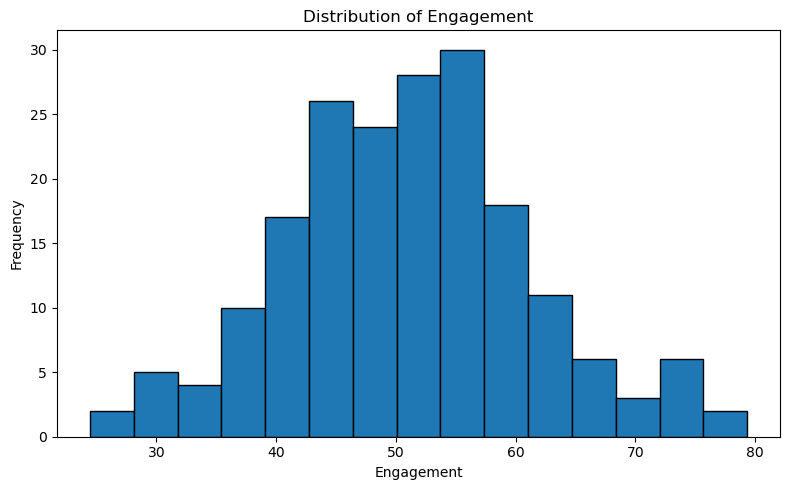

In [158]:
plt.figure(figsize=(8, 5))

plt.hist(
    engagement,
    bins=15,
    edgecolor="black"
)

plt.title("Distribution of Engagement")
plt.xlabel("Engagement")
plt.ylabel("Frequency")

plt.tight_layout()

plt.show()

In [159]:
from scipy.stats import ttest_ind, t

# Fit data only
fit_stats = X_fit.copy()

g1 = fit_stats.loc[
    fit_stats["group"] == "G1",
    "engagement"
].dropna()

g2 = fit_stats.loc[
    fit_stats["group"] == "G2",
    "engagement"
].dropna()

print("G1 count:", len(g1))
print("G2 count:", len(g2))

# Welch's t-test
t_stat, p_value = ttest_ind(
    g1,
    g2,
    equal_var=False,
    alternative="two-sided"
)

print("\nWelch t-test")
print("----------------")
print("t-statistic:", t_stat)
print("p-value:", p_value)

alpha = 0.05

if p_value < alpha:
    print("Decision: Reject H0")
else:
    print("Decision: Fail to reject H0")

G1 count: 84
G2 count: 108

Welch t-test
----------------
t-statistic: 0.7229961865721685
p-value: 0.47065078178032727
Decision: Fail to reject H0


In [160]:
overall = X_fit["engagement"].dropna()

n = len(overall)
mean = overall.mean()
std = overall.std(ddof=1)

standard_error = std / np.sqrt(n)

t_critical = t.ppf(
    0.975,
    df=n-1
)

margin_error = t_critical * standard_error

ci_lower = mean - margin_error
ci_upper = mean + margin_error

print("\n95% Confidence Interval")
print("------------------------")
print("Lower:", ci_lower)
print("Upper:", ci_upper)


95% Confidence Interval
------------------------
Lower: 49.537187510732345
Upper: 52.46645832260099


# Task 2 - Data Preprocessing & Feature Engineering

## F1 — Audit and Partition

In [161]:
print("og data",df.shape)
df_dupl= df.duplicated().sum()
df_dupl
df_clean= df.drop_duplicates().copy()
df
print("Cleaned",df_clean.shape)

og data (305, 7)
Cleaned (300, 7)


In [162]:
print("Original raw shape:", df.shape)
print("Exact duplicates:", df.duplicated().sum())
print("Clean shape:", df_clean.shape)
print("Unique records:", df_clean["record_id"].nunique())

print("\nMissing values:")
print(df_clean.isna().sum())

print("\nTarget counts:")
print(df_clean["response"].value_counts().sort_index())

print("\nTarget proportions:")
print(df_clean["response"].value_counts(normalize=True).sort_index())

Original raw shape: (305, 7)
Exact duplicates: 5
Clean shape: (300, 7)
Unique records: 300

Missing values:
record_id      0
visits        15
recency       15
engagement     0
spend          0
group          0
response       0
dtype: int64

Target counts:
response
0    127
1    173
Name: count, dtype: int64

Target proportions:
response
0    0.423333
1    0.576667
Name: proportion, dtype: float64


In [163]:
print("Fit records:", len(X_fit))
print("Validation records:", len(X_val))
print("Test records:", len(X_test))

fit_ids = set(X_fit["record_id"])
val_ids = set(X_val["record_id"])
test_ids = set(X_test["record_id"])

print("\nFit ∩ Validation:", len(fit_ids & val_ids))
print("Fit ∩ Test:", len(fit_ids & test_ids))
print("Validation ∩ Test:", len(val_ids & test_ids))

assert len(fit_ids & val_ids) == 0
assert len(fit_ids & test_ids) == 0
assert len(val_ids & test_ids) == 0

print("\nAll partitions are disjoint.")

Fit records: 192
Validation records: 48
Test records: 60

Fit ∩ Validation: 0
Fit ∩ Test: 0
Validation ∩ Test: 0

All partitions are disjoint.


## F2 — Transform and Engineer

### 1. MEDIAN IMPUTATION


In [164]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_cols = [
    "visits",
    "recency",
    "engagement",
    "spend"
]

categorical_cols = ["group"]


# 1. MEDIAN IMPUTATION

imputer = SimpleImputer(strategy="median")

# Fit ONLY on fit data
imputer.fit(X_fit[numeric_cols])

# Transform fit, validation and test
X_fit_num = pd.DataFrame(
    imputer.transform(X_fit[numeric_cols]),
    columns=numeric_cols,
    index=X_fit.index
)

X_val_num = pd.DataFrame(
    imputer.transform(X_val[numeric_cols]),
    columns=numeric_cols,
    index=X_val.index
)

X_test_num = pd.DataFrame(
    imputer.transform(X_test[numeric_cols]),
    columns=numeric_cols,
    index=X_test.index
)

### 2. ENGINEERED FEATURE
#### Must be calculated after imputation and before scaling.

In [165]:
X_fit_num["engineered_feature"] = (
    X_fit_num["engagement"] /
    (X_fit_num["recency"] + 1)
)

X_val_num["engineered_feature"] = (
    X_val_num["engagement"] /
    (X_val_num["recency"] + 1)
)

X_test_num["engineered_feature"] = (
    X_test_num["engagement"] /
    (X_test_num["recency"] + 1)
)




### 3. ONE-HOT ENCODING OF GROUP


In [166]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Fit ONLY on fit data
encoder.fit(X_fit[categorical_cols])

X_fit_cat = pd.DataFrame(
    encoder.transform(X_fit[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_fit.index
)

X_val_cat = pd.DataFrame(
    encoder.transform(X_val[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_val.index
)

X_test_cat = pd.DataFrame(
    encoder.transform(X_test[categorical_cols]),
    columns=encoder.get_feature_names_out(categorical_cols),
    index=X_test.index
)

### 4. STANDARD SCALING


In [167]:
numeric_features = [
    "visits",
    "recency",
    "engagement",
    "spend",
    "engineered_feature"
]

scaler = StandardScaler()

# Fit ONLY on fit numeric data
scaler.fit(X_fit_num[numeric_features])

# Transform all partitions
X_fit_scaled = pd.DataFrame(
    scaler.transform(X_fit_num[numeric_features]),
    columns=numeric_features,
    index=X_fit.index
)

X_val_scaled = pd.DataFrame(
    scaler.transform(X_val_num[numeric_features]),
    columns=numeric_features,
    index=X_val.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_num[numeric_features]),
    columns=numeric_features,
    index=X_test.index
)

### 5. COMBINE FEATURES
### Numeric features = scaled
### Group features = NOT scaled

In [168]:
X_fit_trans = pd.concat(
    [X_fit_scaled, X_fit_cat],
    axis=1
)

X_val_trans = pd.concat(
    [X_val_scaled, X_val_cat],
    axis=1
)

X_test_trans = pd.concat(
    [X_test_scaled, X_test_cat],
    axis=1
)

print("Fit transformed shape:", X_fit_trans.shape)
print("Validation transformed shape:", X_val_trans.shape)
print("Test transformed shape:", X_test_trans.shape)

print("\nFinal feature names:")
print(X_fit_trans.columns.tolist())

Fit transformed shape: (192, 7)
Validation transformed shape: (48, 7)
Test transformed shape: (60, 7)

Final feature names:
['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']


## F3 — Leakage Evidence

In [169]:
# 1. TRANSFORMED SHAPES

print("Transformed Shapes")
print("------------------")
print("Fit:", X_fit_trans.shape)
print("Validation:", X_val_trans.shape)
print("Test:", X_test_trans.shape)


# 2. FEATURE NAMES

print("\nFeature Names")
print("-------------")

for i, feature in enumerate(X_fit_trans.columns, start=1):
    print(i, ":", feature)


# 3. CHECK NaN VALUES

print("\nNaN Check")
print("---------")

print("Fit NaN:", X_fit_trans.isna().sum().sum())
print("Validation NaN:", X_val_trans.isna().sum().sum())
print("Test NaN:", X_test_trans.isna().sum().sum())


# 4. CHECK INFINITE VALUES

print("\nInfinite Value Check")
print("--------------------")

print(
    "Fit infinite:",
    np.isinf(X_fit_trans.to_numpy()).sum()
)

print(
    "Validation infinite:",
    np.isinf(X_val_trans.to_numpy()).sum()
)

print(
    "Test infinite:",
    np.isinf(X_test_trans.to_numpy()).sum()
)


# 5. CHECK RECORD_ID AND TARGET

print("\nLeakage Check")
print("-------------")

print(
    "record_id included:",
    "record_id" in X_fit_trans.columns
)

print(
    "response included:",
    "response" in X_fit_trans.columns
)

Transformed Shapes
------------------
Fit: (192, 7)
Validation: (48, 7)
Test: (60, 7)

Feature Names
-------------
1 : visits
2 : recency
3 : engagement
4 : spend
5 : engineered_feature
6 : group_G1
7 : group_G2

NaN Check
---------
Fit NaN: 0
Validation NaN: 0
Test NaN: 0

Infinite Value Check
--------------------
Fit infinite: 0
Validation infinite: 0
Test infinite: 0

Leakage Check
-------------
record_id included: False
response included: False


In [170]:
assert "record_id" not in X_fit_trans.columns
assert "response" not in X_fit_trans.columns

assert X_fit_trans.isna().sum().sum() == 0
assert X_val_trans.isna().sum().sum() == 0
assert X_test_trans.isna().sum().sum() == 0

assert np.isfinite(X_fit_trans.to_numpy()).all()
assert np.isfinite(X_val_trans.to_numpy()).all()
assert np.isfinite(X_test_trans.to_numpy()).all()

print("\n✓ F3 leakage checks passed.")


✓ F3 leakage checks passed.


In [171]:
from pathlib import Path
import joblib

Path("models").mkdir(parents=True, exist_ok=True)

joblib.dump(
    {
        "imputer": imputer,
        "encoder": encoder,
        "scaler": scaler
    },
    "models/preprocessing.pkl"
)

print("✓ Preprocessing saved to models/preprocessing.pkl")

✓ Preprocessing saved to models/preprocessing.pkl


## Explaination
#### **Target**: Excluded because it is what the model predicts.
#### **record_id**: Excluded because it is only an identifier.
#### **Test statistics**: Excluded to prevent data leakage and ensure fair evaluation.

# Task 3 - Supervised Learning

## S1 — Baseline and Classifier

In [172]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression

# Majority-class baseline
dummy = DummyClassifier(
    strategy="most_frequent",
    random_state=42
)

dummy.fit(X_fit_trans, y_fit)

# Logistic Regression
logreg = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logreg.fit(X_fit_trans, y_fit)

print("Models trained successfully.")

Models trained successfully.


In [173]:
print("Target: response")
print("Predictors:", X_fit_trans.columns.tolist())
print("Logistic Regression max_iter: 1000")
print("Random state: 42")

Target: response
Predictors: ['visits', 'recency', 'engagement', 'spend', 'engineered_feature', 'group_G1', 'group_G2']
Logistic Regression max_iter: 1000
Random state: 42


## S2 — Holdout Evaluation

In [174]:
# Predictions on untouched test set
dummy_pred = dummy.predict(X_test_trans)
logreg_pred = logreg.predict(X_test_trans)

# Class-1 probability
logreg_prob = logreg.predict_proba(X_test_trans)[:, 1]

# Metrics
results = pd.DataFrame({
    "Accuracy": [
        accuracy_score(y_test, dummy_pred),
        accuracy_score(y_test, logreg_pred)
    ],
    "Precision": [
        precision_score(y_test, dummy_pred, zero_division=0),
        precision_score(y_test, logreg_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, dummy_pred, zero_division=0),
        recall_score(y_test, logreg_pred, zero_division=0)
    ],
    "F1": [
        f1_score(y_test, dummy_pred, zero_division=0),
        f1_score(y_test, logreg_pred, zero_division=0)
    ]
}, index=["Dummy Baseline", "Logistic Regression"])

print(results)

                     Accuracy  Precision    Recall        F1
Dummy Baseline       0.583333   0.583333  1.000000  0.736842
Logistic Regression  0.816667   0.833333  0.857143  0.845070


Confusion Matrix:
[[19  6]
 [ 5 30]]


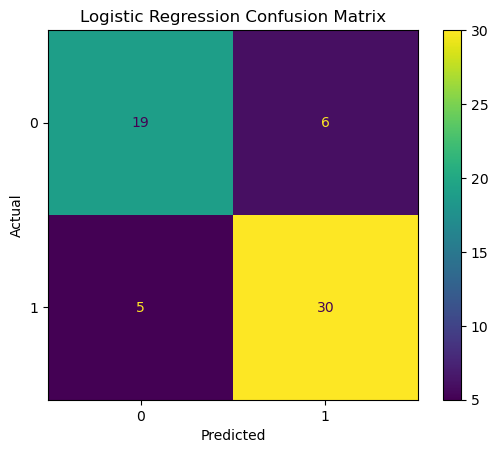

In [175]:
cm = confusion_matrix(y_test, logreg_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["0", "1"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [176]:
from pathlib import Path

Path("outputs").mkdir(parents=True, exist_ok=True)
Path("outputs/figures").mkdir(parents=True, exist_ok=True)



In [177]:
predictions.to_csv("outputs/logistic_test_predictions.csv",index=False)

results.to_csv(
    "outputs/supervised_metrics.csv",
    index=True
)

print("Files saved successfully.")

NameError: name 'predictions' is not defined

## S3 — Interpretation

**False Positive:-  Model predicts 1 (response), but actual value is 0.**

**False Negative:-  Model predicts 0 (no response), but actual value is 1.**

# Task 4 — Unsupervised Learning 

### U1 — K-Means and Selection

In [178]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Numeric features for clustering
cluster_features = [
    "visits",
    "recency",
    "engagement",
    "spend",
    "engineered_feature"
]

X_cluster = X_fit_trans[cluster_features].copy()

print("Clustering shape:", X_cluster.shape)
print("Features used:")
print(cluster_features)

Clustering shape: (192, 5)
Features used:
['visits', 'recency', 'engagement', 'spend', 'engineered_feature']


In [179]:
results_kmeans = []

models_kmeans = {}

for k in [2, 3, 4]:

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    labels = kmeans.fit_predict(X_cluster)

    inertia = kmeans.inertia_
    silhouette = silhouette_score(
        X_cluster,
        labels
    )

    results_kmeans.append({
        "k": k,
        "inertia": inertia,
        "silhouette_score": silhouette
    })

    models_kmeans[k] = kmeans

# Results table
kmeans_results = pd.DataFrame(results_kmeans)

print(kmeans_results)

c:\Users\patel\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\patel\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\patel\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\patel\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

   k     inertia  silhouette_score
0  2  713.030410          0.225909
1  3  613.551097          0.187178
2  4  541.645319          0.190736


In [ ]:
best_k = (
    kmeans_results
    .sort_values(
        by=["silhouette_score", "k"],
        ascending=[False, True]
    )
    .iloc[0]["k"]
)

best_k = int(best_k)

print("Selected k:", best_k)

Selected k: 2


In [ ]:
from pathlib import Path

Path("outputs").mkdir(parents=True, exist_ok=True)

kmeans_results.to_csv(
    "outputs/kmeans_selection.csv",
    index=False
)

print("K-Means selection saved.")

K-Means selection saved.


## U2 — Segment Interpretation

In [ ]:
best_model = models_kmeans[best_k]

cluster_labels = best_model.labels_

clustered_fit = X_fit.copy()

clustered_fit["cluster"] = cluster_labels

print(
    clustered_fit["cluster"].value_counts().sort_index()
)

cluster
0    109
1     83
Name: count, dtype: int64


In [ ]:
profile_features = [
    "visits",
    "recency",
    "engagement",
    "spend"
]

cluster_profile = (
    clustered_fit
    .groupby("cluster")[profile_features]
    .mean()
)

print("Cluster Profiles:")
print(cluster_profile)

Cluster Profiles:
            visits    recency  engagement      spend
cluster                                             
0        49.356176  55.422286   46.092110  50.180550
1        49.539367  43.926750   57.449518  50.969398


In [ ]:
cluster_profile.to_csv(
    "outputs/cluster_profiles.csv"
)

### Cluster IDs are arbitrary because K-Means assigns numbers such as 0, 1, and 2 only as labels; they do not indicate target classes or ranking. We choose clusters using fit-data features only, without using the response target or test data. This prevents data leakage and keeps the clustering unbiased

In [ ]:
clustered_fit[
    ["record_id", "cluster"]
].to_csv(
    "outputs/cluster_assignments.csv",
    index=False
)

print("Cluster assignments saved.")

Cluster assignments saved.


# Task 5 — Deep Learning up to ANN

## D1 — ANN Architecture and Compilation

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Random seed
np.random.seed(42)
tf.random.set_seed(42)

# Convert to NumPy
X_train_ann = X_fit_trans.to_numpy()
X_val_ann = X_val_trans.to_numpy()
X_test_ann = X_test_trans.to_numpy()

y_train_ann = y_fit.to_numpy()
y_val_ann = y_val.to_numpy()
y_test_ann = y_test.to_numpy()

# Input size
input_width = X_train_ann.shape[1]

print("Input feature count:", input_width)

Input feature count: 7


In [ ]:
model = keras.Sequential([
    layers.Input(shape=(input_width,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 273 (1.07 KB)

 Trainable params: 273 (1.07 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
trainable_params = np.sum([
    np.prod(v.shape)
    for v in model.trainable_variables
])

print("Trainable parameters:", trainable_params)

Trainable parameters: 273


## D2 — Training and Validation

In [180]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train_ann,
    y_train_ann,
    validation_data=(X_val_ann, y_val_ann),
    epochs=50,
    batch_size=16,
    callbacks=[early_stopping],
    verbose=1
)

NameError: name 'keras' is not defined

In [ ]:
actual_epochs = len(history.history["loss"])

print("Actual epochs trained:", actual_epochs)
print("Random seed:", 42)

Actual epochs trained: 46
Random seed: 42


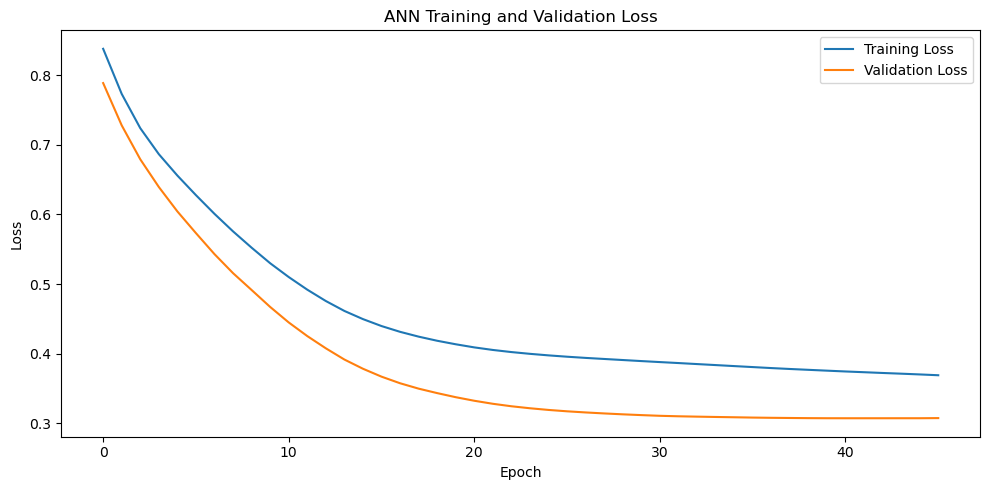

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ANN Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()

plt.savefig(
    "outputs/figures/ann_loss_curve.png",
    dpi=150
)

plt.show()

## D3 — Comparison and Evidence

In [ ]:
# Probability predictions
ann_prob = model.predict(
    X_test_ann,
    verbose=0
).ravel()

# Threshold = 0.5
ann_pred = (ann_prob >= 0.5).astype(int)

# Metrics
ann_accuracy = accuracy_score(
    y_test_ann,
    ann_pred
)

ann_precision = precision_score(
    y_test_ann,
    ann_pred,
    zero_division=0
)

ann_recall = recall_score(
    y_test_ann,
    ann_pred,
    zero_division=0
)

ann_f1 = f1_score(
    y_test_ann,
    ann_pred,
    zero_division=0
)

print("ANN Test Results")
print("----------------")
print("Accuracy :", ann_accuracy)
print("Precision:", ann_precision)
print("Recall   :", ann_recall)
print("F1 Score :", ann_f1)

ANN Test Results
----------------
Accuracy : 0.8166666666666667
Precision: 0.8333333333333334
Recall   : 0.8571428571428571
F1 Score : 0.8450704225352113


In [ ]:
print("Logistic Regression F1:",
      f1_score(y_test, logreg_pred, zero_division=0))

print("ANN F1:",
      ann_f1)

Logistic Regression F1: 0.8450704225352113
ANN F1: 0.8450704225352113


In [ ]:
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "ANN"
    ],
    "Accuracy": [
        accuracy_score(y_test, logreg_pred),
        ann_accuracy
    ],
    "Precision": [
        precision_score(y_test, logreg_pred, zero_division=0),
        ann_precision
    ],
    "Recall": [
        recall_score(y_test, logreg_pred, zero_division=0),
        ann_recall
    ],
    "F1": [
        f1_score(y_test, logreg_pred, zero_division=0),
        ann_f1
    ]
})

print(comparison)


                 Model  Accuracy  Precision    Recall       F1
0  Logistic Regression  0.816667   0.833333  0.857143  0.84507
1                  ANN  0.816667   0.833333  0.857143  0.84507


In [ ]:
ann_predictions = pd.DataFrame({
    "record_id": X_test["record_id"],
    "true_label": y_test_ann,
    "predicted_label": ann_pred,
    "class_1_probability": ann_prob
})

ann_predictions.to_csv(
    "outputs/ann_test_predictions.csv",
    index=False
)

In [ ]:
from pathlib import Path

Path("models").mkdir(
    parents=True,
    exist_ok=True
)

model.save(
    "models/ann_model.keras"
)

print("ANN model saved successfully.")

ANN model saved successfully.


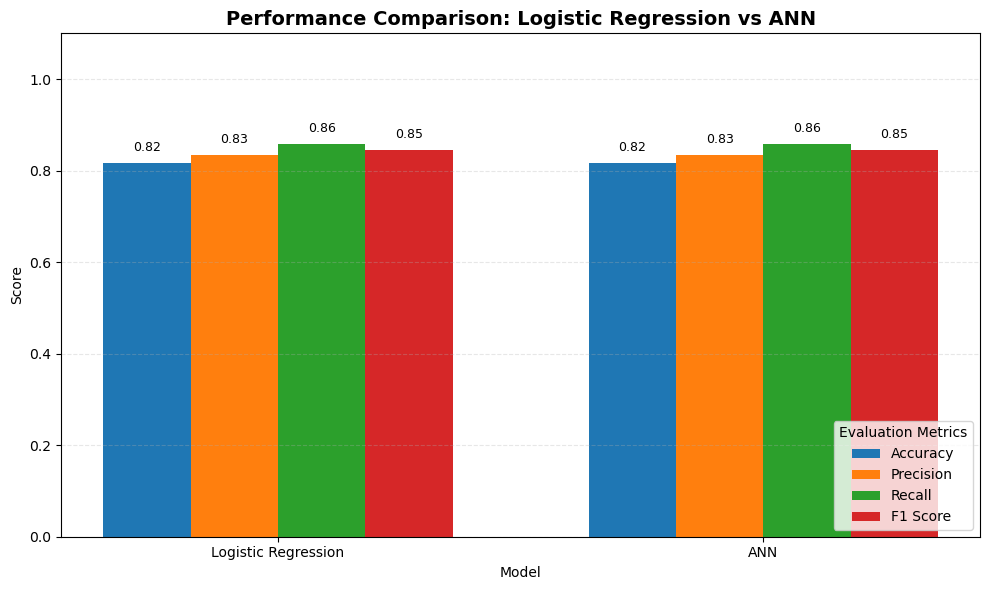

In [ ]:
models = ["Logistic Regression", "ANN"]

accuracy = [
    accuracy_score(y_test, logreg_pred),
    ann_accuracy
]

precision = [
    precision_score(y_test, logreg_pred, zero_division=0),
    ann_precision
]

recall = [
    recall_score(y_test, logreg_pred, zero_division=0),
    ann_recall
]

f1 = [
    f1_score(y_test, logreg_pred, zero_division=0),
    ann_f1
]

x = np.arange(len(models))
width = 0.18

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - 1.5*width, accuracy, width, label="Accuracy")
bars2 = ax.bar(x - 0.5*width, precision, width, label="Precision")
bars3 = ax.bar(x + 0.5*width, recall, width, label="Recall")
bars4 = ax.bar(x + 1.5*width, f1, width, label="F1 Score")

# Add values above bars
for bars in [bars1, bars2, bars3, bars4]:
    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.02,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=9
        )

ax.set_title(
    "Performance Comparison: Logistic Regression vs ANN",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Model")
ax.set_ylabel("Score")

ax.set_xticks(x)
ax.set_xticklabels(models)

ax.set_ylim(0, 1.1)

ax.legend(
    title="Evaluation Metrics",
    loc="lower right"
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    "outputs/figures/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()